# Full pipeline validation on real WRDS data

Runs the complete chain **data → analytics → signals → portfolio** on real SPX data, using the team's own code
as merged from `feature/signals` (Adam) and `backtest/portfolio` (Justine). No module is re-implemented here:
the notebook only calls their functions and checks the results.

The checks replay, on real data, the tests that Adam (`signal_demo.ipynb`, `tests/test_signals.py`) and
Justine (`backtest-test.ipynb`, `tests/test_backtester.py`) ran on dummy data:

| Their dummy-data test | Real-data check here |
|---|---|
| Premium bound ½·SVIX² for SVIX = 0.20 (Adam) | Daily bound and target weight over the period (§2) |
| Weight = min(1, ½·SVIX²), execution at t + 1 business day, market data propagated (Adam) | Same, on every real signal (§2) |
| Ledger invariants: equity = cash + assets, equity > 0, weight = target, no look-ahead (Justine) | Same, on the real ledger (§3.1) |
| Order of signals does not change the result (Justine, test E) | Real signals shuffled (§3.1) |
| Daily return consistent with equity (Justine, test F) | Same (§3.1) |
| Transaction cost, cash interest, dividends (Justine, tests A–C) | Day-by-day P&L decomposition on real prices (§3.2) |
| Sharpe, Sortino, Calmar, drawdown recomputed by hand (Justine) | Same, on the real equity curve (§3.3) |
| 3-panel chart of the dummy pipeline (Justine) | Same chart on real data, with a 100% SPX benchmark (§3.4) |

Hard checks are `assert`s: if the notebook runs to the end, they all passed. Issues that do not block the run
are printed as **⚠️ findings**.

In [ ]:
import sys
from pathlib import Path

# The notebook runs from notebooks/: add the project root to the path to import src.
sys.path.insert(0, str(Path.cwd().parent))

In [ ]:
import pickle
import random
import time
from dataclasses import replace
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analytics import VarianceCalculator
from src.data.wrds_loader import WRDSOptionLoader
from src.portfolio import PortfolioSimulator
from src.signals import SignalGenerator

# Test period: includes the April 2025 tariff shock, to stress the pipeline.
START, END = datetime(2025, 1, 2), datetime(2025, 6, 30)

# Same backtest parameters as Justine's notebook.
INITIAL_CAPITAL = 1_000_000.0
TRANSACTION_COST_BPS = 5.0
ANN_FACTOR = 252

# Results are cached outside the repo, so a re-run does not query WRDS again.
CACHE = Path.home() / ".svix_cache" / f"pipeline_v2_{START:%Y%m%d}_{END:%Y%m%d}.pkl"

loader = WRDSOptionLoader()

WRDS recommends setting up a .pgpass file.
Created .pgpass file successfully.
You can create this file yourself at any time with the create_pgpass_file() function.
Loading library list...
Done


## 1. Data + analytics: daily SVIX and VIX

For each SPX trading day: `get_interpolation_chains` (data) → `compute_metrics` (analytics). Dates where a module
fails are recorded with their error instead of stopping the loop. First run: a few minutes (WRDS queries);
later runs use the cache.

In [ ]:
def trading_days(start: datetime, end: datetime) -> list:
    days = []
    for year in range(start.year, end.year + 1):
        df = loader._run_query(
            f"SELECT date FROM optionm.secprd{year} WHERE secid = 108105 AND date BETWEEN %(s)s AND %(e)s ORDER BY date",
            {"s": start.date(), "e": end.date()},
        )
        days += [datetime.combine(d, datetime.min.time()) for d in df["date"]]
    return days


def save(state: dict) -> None:
    CACHE.parent.mkdir(exist_ok=True)
    with open(CACHE, "wb") as f:
        pickle.dump(state, f)


# Resumable: days already computed are kept in the cache, so an interrupted run restarts where it stopped.
state = {"days": None, "done": {}}
if CACHE.exists():
    with open(CACHE, "rb") as f:
        state = pickle.load(f)
if state["days"] is None:
    state["days"] = trading_days(START, END)
    save(state)
days = state["days"]

calculator = VarianceCalculator()
todo = [d for d in days if d not in state["done"]]
print(f"{len(days) - len(todo)} days already in cache, {len(todo)} to compute")
t0 = time.time()
for i, day in enumerate(todo, 1):
    try:
        chains = loader.get_interpolation_chains(day, target_days=30)
        state["done"][day] = calculator.compute_metrics(chains, target_days=30)
    except Exception as exc:  # recorded, reported below
        state["done"][day] = f"{type(exc).__name__}: {exc}"
    if i % 5 == 0 or i == len(todo):
        save(state)
        elapsed = time.time() - t0
        eta = elapsed / i * (len(todo) - i)
        print(f"{i}/{len(todo)} days ({day:%Y-%m-%d}), {elapsed / 60:.1f} min elapsed, ~{eta / 60:.1f} min left", flush=True)

history = [state["done"][d] for d in days if not isinstance(state["done"][d], str)]
failures = [{"date": d, "error": state["done"][d]} for d in days if isinstance(state["done"][d], str)]

metrics_df = pd.DataFrame([vars(m) for m in history]).set_index("date")
metrics_df.index = pd.to_datetime(metrics_df.index)
print(f"{len(history)} / {len(days)} trading days computed ({len(history) / len(days):.1%}), {len(failures)} failures")
pd.DataFrame(failures)

0 days already in cache, 122 to compute
5/122 days (2025-01-08), 0.1 min elapsed, ~1.6 min left
10/122 days (2025-01-16), 0.1 min elapsed, ~1.5 min left
15/122 days (2025-01-24), 0.2 min elapsed, ~1.4 min left
20/122 days (2025-01-31), 0.3 min elapsed, ~1.3 min left
25/122 days (2025-02-07), 0.3 min elapsed, ~1.3 min left
30/122 days (2025-02-14), 0.4 min elapsed, ~1.3 min left
35/122 days (2025-02-24), 0.5 min elapsed, ~1.2 min left
40/122 days (2025-03-03), 0.6 min elapsed, ~1.2 min left
45/122 days (2025-03-10), 0.6 min elapsed, ~1.1 min left
50/122 days (2025-03-17), 0.7 min elapsed, ~1.0 min left
55/122 days (2025-03-24), 0.8 min elapsed, ~1.0 min left
60/122 days (2025-03-31), 0.9 min elapsed, ~0.9 min left
65/122 days (2025-04-07), 1.0 min elapsed, ~0.8 min left
70/122 days (2025-04-14), 1.0 min elapsed, ~0.8 min left
75/122 days (2025-04-22), 1.1 min elapsed, ~0.7 min left
80/122 days (2025-04-29), 1.2 min elapsed, ~0.6 min left
85/122 days (2025-05-06), 1.3 min elapsed, ~0.6 m

""


Correlation with CBOE VIX: 0.998
Mean gap: -0.36 pts, mean absolute gap: 0.41 pts


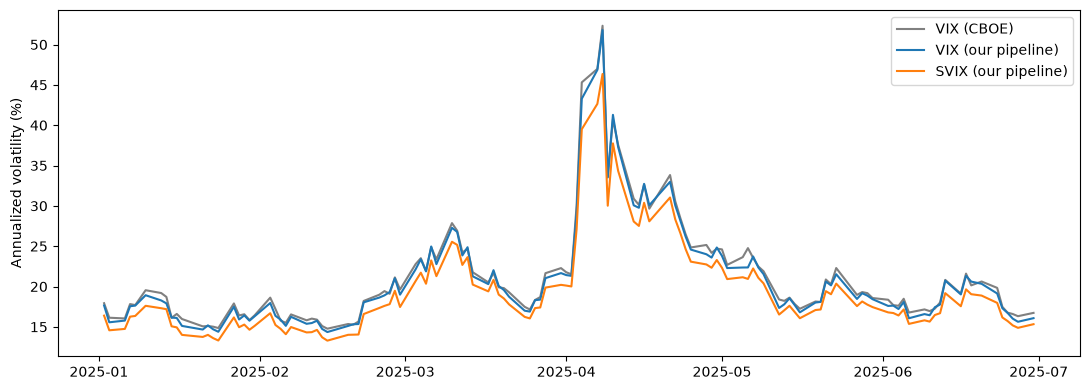

In [ ]:
# Cross-check against the official CBOE VIX (yfinance).
import yfinance as yf

cboe = yf.download("^VIX", start=START, end=END + pd.Timedelta(days=1), progress=False, auto_adjust=False)["Close"]
cboe = cboe.squeeze()
cboe.index = pd.to_datetime(cboe.index)
if cboe.index.tz is not None:
    cboe.index = cboe.index.tz_convert(None)
cboe.index = cboe.index.normalize()

comp = pd.DataFrame({"VIX (ours)": metrics_df["vix_annualized"] * 100, "VIX (CBOE)": cboe}).dropna()
comp["gap"] = comp["VIX (ours)"] - comp["VIX (CBOE)"]
print(f"Correlation with CBOE VIX: {comp['VIX (ours)'].corr(comp['VIX (CBOE)']):.3f}")
print(f"Mean gap: {comp['gap'].mean():.2f} pts, mean absolute gap: {comp['gap'].abs().mean():.2f} pts")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(comp.index, comp["VIX (CBOE)"], label="VIX (CBOE)", color="grey")
ax.plot(comp.index, comp["VIX (ours)"], label="VIX (our pipeline)")
ax.plot(metrics_df.index, metrics_df["svix_annualized"] * 100, label="SVIX (our pipeline)")
ax.set_ylabel("Annualized volatility (%)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Checks on the analytics output
assert len(history) / len(days) > 0.95, "More than 5% of days failed: see the failures table"
assert (metrics_df["svix_annualized"] > 0).all() and (metrics_df["svix_annualized"] < 2).all()
assert comp["VIX (ours)"].corr(comp["VIX (CBOE)"]) > 0.95, "Our VIX does not track the CBOE VIX"
share_premium_positive = (metrics_df["vix_annualized"] >= metrics_df["svix_annualized"]).mean()
print(f"Days with VIX >= SVIX (expected for a negatively skewed market): {share_premium_positive:.1%}")
metrics_df[["svix_annualized", "vix_annualized", "integration_points", "min_strike_used", "max_strike_used"]].describe()

Days with VIX >= SVIX (expected for a negatively skewed market): 100.0%


,svix_annualized,vix_annualized,integration_points,min_strike_used,max_strike_used
count,122.000000,122.000000,122.000000,122.000000,122.000000
mean,0.194607,0.208111,54.803279,2283.606557,6972.131148
std,0.059074,0.065295,27.746979,498.984201,617.681923
min,0.132878,0.143524,25.000000,1000.000000,6000.000000
25%,0.157435,0.166163,40.250000,2000.000000,6600.000000
50%,0.175633,0.186785,51.000000,2200.000000,6800.000000
75%,0.209353,0.223373,60.000000,2600.000000,7175.000000
max,0.463490,0.517933,217.000000,3800.000000,11000.000000


## 2. Signals (Adam): `SignalGenerator.generate_signals`

Adam's `signal_demo.ipynb` computes the premium bound ½·SVIX² for a single SVIX of 20%, and
`tests/test_signals.py` checks the weight formula, the next-business-day execution and the propagation of
market data on one dummy `VolatilityMetrics`. Here, the same function runs on the full real history.

In [ ]:
signals = SignalGenerator().generate_signals(history)
sig_df = pd.DataFrame([vars(s) for s in signals]).set_index("signal_date")
sig_df.index = pd.to_datetime(sig_df.index)

# One signal per computed day
assert len(signals) == len(history)
# Weight = min(1, 0.5 * SVIX^2), bounded and finite (test_derive_target_weight, signal_demo)
premium_bound = 0.5 * metrics_df["svix_annualized"] ** 2
assert np.allclose(sig_df["target_weight"].values, np.minimum(1.0, premium_bound.values))
assert sig_df["target_weight"].between(-1, 1).all() and np.isfinite(sig_df["target_weight"]).all()
# No look-ahead: execution on the next business day (test_generate_signals)
assert (pd.to_datetime(sig_df["target_execution_date"]) == sig_df.index + pd.offsets.BDay(1)).all()
# Market data propagated unchanged (test_generate_signals)
for col_sig, col_met in [
    ("underlying_price_at_signal", "underlying_price"),
    ("risk_free_rate", "risk_free_rate"),
    ("dividend_yield", "dividend_yield"),
]:
    assert np.allclose(sig_df[col_sig].values, metrics_df[col_met].values), col_sig

print(f"Premium bound 0.5·SVIX²: mean {premium_bound.mean():.2%}, min {premium_bound.min():.2%}, max {premium_bound.max():.2%}")
print(f"Days where the 100% cap binds: {(premium_bound >= 1).sum()}")
print(f"Days with a short position (weight < 0): {(sig_df['target_weight'] < 0).sum()}")

# ⚠️ Finding: BDay(1) skips weekends but not US market holidays
trading_set = {pd.Timestamp(d) for d in days}
exec_dates = pd.to_datetime(sig_df["target_execution_date"])
in_period = exec_dates <= pd.Timestamp(days[-1])
on_holiday = sig_df[in_period & ~exec_dates.isin(trading_set)]
if len(on_holiday):
    print(f"⚠️ {len(on_holiday)} signals are scheduled for execution on a day the market is closed:")
    print(on_holiday[["target_execution_date"]])

Premium bound 0.5·SVIX²: mean 2.07%, min 0.88%, max 10.74%
Days where the 100% cap binds: 0
Days with a short position (weight < 0): 0
⚠️ 6 signals are scheduled for execution on a day the market is closed:
            target_execution_date
signal_date                      
2025-01-08             2025-01-09
2025-01-17             2025-01-20
2025-02-14             2025-02-17
2025-04-17             2025-04-18
2025-05-23             2025-05-26
2025-06-18             2025-06-19


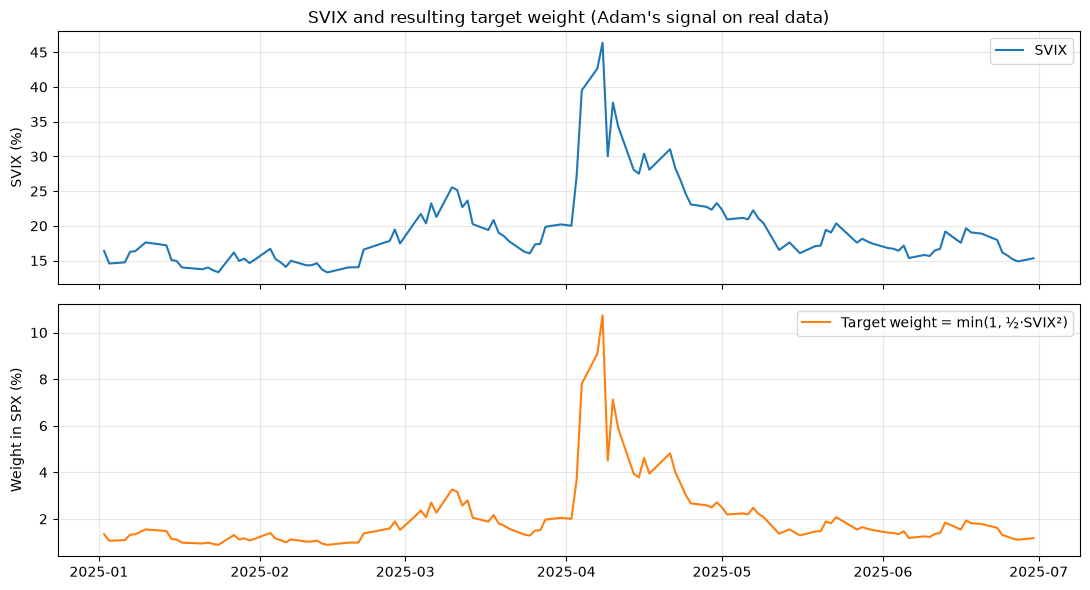

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(metrics_df.index, metrics_df["svix_annualized"] * 100, label="SVIX")
axes[0].set_ylabel("SVIX (%)")
axes[0].set_title("SVIX and resulting target weight (Adam's signal on real data)")
axes[1].plot(sig_df.index, sig_df["target_weight"] * 100, color="tab:orange", label="Target weight = min(1, ½·SVIX²)")
axes[1].set_ylabel("Weight in SPX (%)")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Portfolio (Justine): `PortfolioSimulator.run_simulation`

### 3.1 Ledger invariants (Justine's consistency tests, tests D, E, F)

In [ ]:
sim = PortfolioSimulator(
    initial_capital=INITIAL_CAPITAL, transaction_cost_bps=TRANSACTION_COST_BPS, annualization_factor=ANN_FACTOR
)
ledger = sim.run_simulation(signals)
sorted_signals = sorted(signals, key=lambda s: s.target_execution_date)

# No early stop (ruin) and chronological ledger
assert len(ledger) == len(signals), "Simulation stopped early (ruin?)"
assert ledger.index.is_monotonic_increasing
# 1. Equity = cash + assets
assert np.allclose(ledger["Total_Equity"], ledger["Cash"] + ledger["Asset_Value"])
# 2. Equity strictly positive
assert (ledger["Total_Equity"] > 0).all()
# 3. Realized weight = target weight (test D)
assert np.allclose(ledger["Position_Weight"].to_numpy(), [s.target_weight for s in sorted_signals])
# 4. No look-ahead: each row is dated after its signal
assert all(pd.Timestamp(d) > pd.Timestamp(s.signal_date) for d, s in zip(ledger.index, sorted_signals))
# 5. Daily_Return consistent with equity (test F)
eq = ledger["Total_Equity"].to_numpy()
assert np.allclose(ledger["Daily_Return"].to_numpy(), eq / np.r_[INITIAL_CAPITAL, eq[:-1]] - 1)
# 6. Order of the signals does not change the result (test E)
shuffled = signals.copy()
random.Random(0).shuffle(shuffled)
pd.testing.assert_frame_equal(
    ledger, PortfolioSimulator(INITIAL_CAPITAL, TRANSACTION_COST_BPS, ANN_FACTOR).run_simulation(shuffled)
)
# 7. Metrics stored on the instance (test H)
assert set(sim.metrics) == {"Sharpe", "Sortino", "Calmar", "Max_Drawdown"}

print("OK ledger invariants on real data")
ledger.tail()

OK ledger invariants on real data


,Position_Weight,Cash,Asset_Value,Total_Equity,Daily_Return
Date,,,,,
2025-06-25,0.013059,1.015839e+06,13441.613662,1.029281e+06,0.000351
2025-06-26,0.012359,1.016737e+06,12722.598651,1.029459e+06,0.000174
2025-06-27,0.011517,1.017881e+06,11859.781317,1.029740e+06,0.000273
2025-06-30,0.011065,1.018585e+06,11396.608576,1.029982e+06,0.000235
2025-07-01,0.011746,1.018120e+06,12101.341790,1.030221e+06,0.000232


### 3.2 Day-by-day P&L decomposition (Justine's tests A, B, C on real prices)

Justine checked one hand-computed day each for the transaction cost, the cash interest and the dividend.
Here, every real day is decomposed: the change in equity must equal market P&L + interest on cash + dividends
on the position − transaction cost, and the implied cost must match |Δweight| × equity × 5 bp.

In [ ]:
P = np.array([s.underlying_price_at_signal for s in sorted_signals])
r = np.array([s.risk_free_rate for s in sorted_signals])
q = np.array([s.dividend_yield for s in sorted_signals])
w = np.array([s.target_weight for s in sorted_signals])
dt, tc = 1 / ANN_FACTOR, TRANSACTION_COST_BPS / 10_000

cash_prev = np.r_[INITIAL_CAPITAL, ledger["Cash"].to_numpy()[:-1]]
shares_prev = np.r_[0.0, ledger["Asset_Value"].to_numpy()[:-1] / P[:-1]]
equity_prev = np.r_[INITIAL_CAPITAL, ledger["Total_Equity"].to_numpy()[:-1]]

market_pnl = shares_prev * (P - np.r_[P[0], P[:-1]])
interest = cash_prev * r * dt
dividends = shares_prev * P * q * dt
equity_before_trade = equity_prev + market_pnl + interest + dividends
implied_cost = equity_before_trade - ledger["Total_Equity"].to_numpy()
expected_cost = np.abs(w - shares_prev * P / equity_before_trade) * equity_before_trade * tc

assert (implied_cost >= -1e-6).all(), "Negative transaction cost"
assert np.allclose(implied_cost, expected_cost, atol=1e-6), "Equity change not explained by P&L components"

pnl = pd.Series(
    {
        "Market P&L": market_pnl.sum(),
        "Interest on cash": interest.sum(),
        "Dividends": dividends.sum(),
        "Transaction costs": -implied_cost.sum(),
    }
)
pnl["Total"] = pnl.sum()
assert np.isclose(pnl["Total"], ledger["Total_Equity"].iloc[-1] - INITIAL_CAPITAL)
print("OK every daily equity change is fully explained")
pnl.round(2).to_frame("P&L ($)")

OK every daily equity change is fully explained


,P&L ($)
Market P&L,8767.61
Interest on cash,21614.77
Dividends,87.61
Transaction costs,-249.02
Total,30220.98


### 3.3 Risk metrics recomputed independently (Justine's `compute_risk_metrics` test)

In [ ]:
curve = pd.Series(np.r_[INITIAL_CAPITAL, ledger["Total_Equity"].to_numpy()])
rets = curve.pct_change().dropna()
rf_avg = np.mean([s.risk_free_rate for s in signals])
ex = rets - rf_avg / ANN_FACTOR

ref = {
    "Sharpe": ex.mean() / ex.std() * np.sqrt(ANN_FACTOR),
    "Sortino": ex.mean() / np.sqrt((ex.clip(upper=0) ** 2).mean()) * np.sqrt(ANN_FACTOR),
    "Max_Drawdown": (curve / curve.cummax() - 1).min(),
}
ann_return = (curve.iloc[-1] / curve.iloc[0]) ** (ANN_FACTOR / len(rets)) - 1
ref["Calmar"] = ann_return / abs(ref["Max_Drawdown"])

for key, value in ref.items():
    assert np.isclose(sim.metrics[key], value), (key, sim.metrics[key], value)

print("OK simulator metrics match the independent recomputation")
pd.DataFrame({"Simulator": sim.metrics, "Recomputed": ref}).round(4)

OK simulator metrics match the independent recomputation


,Simulator,Recomputed
Sharpe,1.0432,1.0432
Sortino,3.1411,3.1411
Calmar,15.2980,15.2980
Max_Drawdown,-0.0041,-0.0041


### 3.4 Results on real data, against a 100% SPX benchmark

The benchmark runs Justine's simulator with a constant weight of 1 on the same real signals. Its equity must
follow the SPX price return, plus the dividends it credits, minus one 5 bp entry cost: this validates the
accounting on real prices, independently of Adam's signal.

In [ ]:
bench_signals = [replace(s, target_weight=1.0) for s in signals]
bench = PortfolioSimulator(INITIAL_CAPITAL, TRANSACTION_COST_BPS, ANN_FACTOR)
bench_ledger = bench.run_simulation(bench_signals)

spx_return = P[-1] / P[0] - 1
bench_return = bench_ledger["Total_Equity"].iloc[-1] / INITIAL_CAPITAL - 1
div_carry = (q[:-1] * P[:-1] / P[0]).sum() / ANN_FACTOR
print(f"SPX price return:          {spx_return:+.2%}")
print(f"Benchmark (weight = 1):    {bench_return:+.2%}")
print(f"Difference:                {bench_return - spx_return:+.2%} (expected ≈ dividends {div_carry:+.2%} − 5 bp)")
assert abs((bench_return - spx_return) - (div_carry - tc)) < 0.005

print("\nStrategy metrics: ", {k: round(v, 4) for k, v in sim.metrics.items()})
print("Benchmark metrics:", {k: round(v, 4) for k, v in bench.metrics.items()})

SPX price return:          +5.73%
Benchmark (weight = 1):    +6.15%
Difference:                +0.41% (expected ≈ dividends +0.42% − 5 bp)

Strategy metrics:  {'Sharpe': np.float64(1.0432), 'Sortino': np.float64(3.1411), 'Calmar': np.float64(15.298), 'Max_Drawdown': np.float64(-0.0041)}
Benchmark metrics: {'Sharpe': np.float64(0.4396), 'Sortino': np.float64(0.6559), 'Calmar': np.float64(0.6971), 'Max_Drawdown': np.float64(-0.1881)}


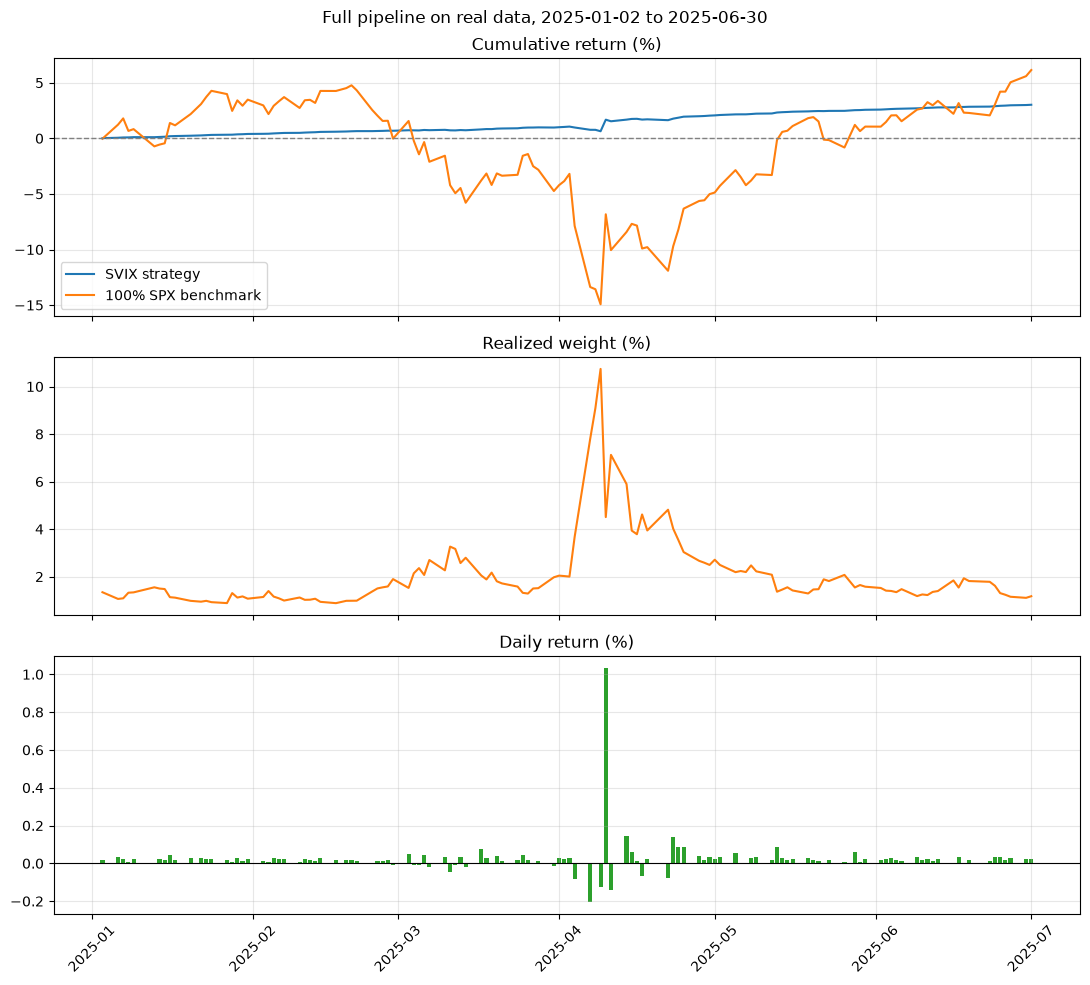

In [ ]:
# Justine's 3-panel chart, on real data
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

axes[0].plot(ledger.index, (ledger["Total_Equity"] / INITIAL_CAPITAL - 1) * 100, label="SVIX strategy")
axes[0].plot(bench_ledger.index, (bench_ledger["Total_Equity"] / INITIAL_CAPITAL - 1) * 100, label="100% SPX benchmark")
axes[0].axhline(0, ls="--", color="gray", lw=1)
axes[0].set_title("Cumulative return (%)")
axes[0].legend()

axes[1].plot(ledger.index, ledger["Position_Weight"] * 100, color="tab:orange")
axes[1].set_title("Realized weight (%)")

axes[2].bar(ledger.index, ledger["Daily_Return"] * 100, color="tab:green", width=0.8)
axes[2].axhline(0, color="black", lw=0.8)
axes[2].set_title("Daily return (%)")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle(f"Full pipeline on real data, {START:%Y-%m-%d} to {END:%Y-%m-%d}", fontsize=12)
plt.tight_layout()
plt.show()

## Findings (SPX, 2025-01-02 to 2025-06-30, 122 trading days)

All hard checks pass: the full pipeline (data → analytics → signals → portfolio) runs end to end on real WRDS data
with the team's own code, merged from `feature/signals` and `backtest/portfolio`.

### 1. Data + analytics
- **122 / 122 trading days computed, 0 failures** (≈ 2 min of WRDS queries).
- Our VIX tracks the official CBOE VIX very closely: **correlation 0.998**, mean gap −0.36 pt, mean absolute gap 0.41 pt.
  The slight downward gap is consistent with the OTM tail truncation by the liquidity filter (see notebook 01).
- **VIX ≥ SVIX on 100% of days**, as expected in a negatively skewed market.
- SVIX averages 19.5% (range 13.3%–46.3%, peak during the April 2025 tariff shock).
- Integration grid: 25 to 217 OTM strikes per chain (mean 55); strike range used from 1,000–3,800 up to 6,000–11,000.

### 2. Signals
- Every check passes: weight = min(1, ½·SVIX²), bounded, execution at t + 1 business day, spot / rate / dividend
  propagated unchanged.
- **The resulting exposure is very small**: target weight averages **2.07%** (min 0.88%, max 10.74% in April).
  The 100% cap never binds and the strategy is never short. The portfolio is therefore ~98% cash.
  The scaling factor (currently k = 1) needs to be calibrated, as noted in the code.
- ⚠️ **6 signals are scheduled on US market holidays**, because `BDay(1)` skips weekends but not exchange holidays:
  2025-01-09 (national day of mourning), 01-20 (MLK Day), 02-17 (Presidents' Day), 04-18 (Good Friday),
  05-26 (Memorial Day), 06-19 (Juneteenth). An exchange calendar should be used instead.

### 3. Portfolio
- Every ledger invariant holds on real data: equity = cash + assets, equity > 0, realized weight = target weight,
  rows dated after their signal, daily returns consistent with equity, and **the result does not depend on the order
  of the signals**.
- **Every daily equity change is fully explained** by its components (market P&L + interest + dividends − costs),
  and each implied transaction cost equals |Δweight| × equity × 5 bp:

  | Component | P&L ($) |
  |---|---|
  | Market P&L | +8,768 |
  | Interest on cash | +21,615 |
  | Dividends | +88 |
  | Transaction costs | −249 |
  | **Total** | **+30,221 (+3.02%)** |

- Sharpe, Sortino, Calmar and max drawdown match an independent recomputation exactly.
- **Benchmark check on real prices**: with a constant 100% weight, the simulator returns +6.15% vs +5.73% for the SPX
  price index. The +0.41% difference matches the expected dividends (+0.42%) minus the 5 bp entry cost, which validates
  the accounting on real prices.

### 4. Strategy results (indicative only)

| | SVIX strategy | 100% SPX |
|---|---|---|
| Sharpe | 1.04 | 0.44 |
| Sortino | 3.14 | 0.66 |
| Max drawdown | −0.41% | −18.81% |

These numbers should **not** be read as performance yet:
- ~72% of the P&L is interest on cash, because the exposure is only ~2%.
- The higher Sharpe mostly comes from the April spike in SVIX (weight up to 10.7%) just before the rebound, and
  **trades are valued at the signal-day close** (`underlying_price_at_signal`) while the contract executes at t + 1.
  This timing gives a small look-ahead advantage and must be fixed before interpreting performance.
- Calmar (15.3) is inflated by the tiny drawdown and is not meaningful here.
- One semester only; results must be confirmed over a longer history.

### Action items
- **Signals (Adam)**: calibrate the scaling of the weight; replace `BDay(1)` with an exchange calendar.
- **Portfolio (Justine)**: price execution at t + 1 instead of the signal-day close; fix `run_simulation([])`
  (KeyError, already noted in her notebook); fix the ruff errors in `backtest-test.ipynb` (CI will fail);
  remove the committed `src/portfolio/.ipynb_checkpoints/backtester-checkpoint.py`.
- **Main**: `main.py` imports outdated class names (`VariancePremiumCalculator`, `AlphaSignalGenerator`) and crashes.
- **Data**: extend the validation over several years, including stress periods (2020, 2022).